# 2.3 Piecewise regression and splines

`monthly_spend` vs. `tenure_months` was built with a diminishing-returns
("loyalty plateaus") shape -- a textbook case where a single straight line
underfits, and a piecewise-linear or spline fit does much better.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


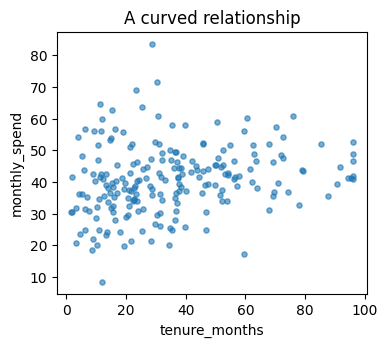

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

Xtr, Xte, ytr, yte = train_test_split(df[["tenure_months"]], df["monthly_spend"], test_size=0.3, random_state=0)

fig, ax = plt.subplots(figsize=(4, 3.4))
ax.scatter(Xtr, ytr, s=14, alpha=0.6)
ax.set_xlabel("tenure_months"); ax.set_ylabel("monthly_spend"); ax.set_title("A curved relationship")
plt.show()

## Baseline: plain linear fit

In [3]:
linear_model = LinearRegression().fit(Xtr, ytr)
r2_linear = r2_score(yte, linear_model.predict(Xte))
print(f"Plain linear R^2 (test) = {r2_linear:.3f}")

Plain linear R^2 (test) = 0.062


## Non-linear regression: piecewise functions

In [4]:
def piecewise_features(x, knot):
    x = np.asarray(x).reshape(-1)
    return np.column_stack([x, np.clip(x - knot, 0, None)])

knot = 30  # months -- roughly where the curve visibly bends
Xtr_pw = piecewise_features(Xtr["tenure_months"], knot)
Xte_pw = piecewise_features(Xte["tenure_months"], knot)

piecewise_model = LinearRegression().fit(Xtr_pw, ytr)
r2_piecewise = r2_score(yte, piecewise_model.predict(Xte_pw))
print(f"Piecewise-linear R^2 (test, knot at {knot} months) = {r2_piecewise:.3f}")

Piecewise-linear R^2 (test, knot at 30 months) = 0.047


## Non-linear regression: regression splines

In [5]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline

spline_model = make_pipeline(
    SplineTransformer(degree=3, n_knots=5),
    LinearRegression(),
).fit(Xtr, ytr)
r2_spline = r2_score(yte, spline_model.predict(Xte))
print(f"Spline regression R^2 (test) = {r2_spline:.3f}")

Spline regression R^2 (test) = 0.070


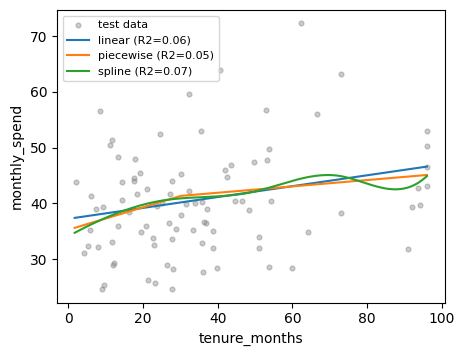

In [6]:
grid = pd.DataFrame({"tenure_months": np.linspace(df.tenure_months.min(), df.tenure_months.max(), 200)})

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.scatter(Xte, yte, s=12, alpha=0.4, color="grey", label="test data")
ax.plot(grid, linear_model.predict(grid), label=f"linear (R2={r2_linear:.2f})")
ax.plot(grid, piecewise_model.predict(piecewise_features(grid["tenure_months"], knot)), label=f"piecewise (R2={r2_piecewise:.2f})")
ax.plot(grid, spline_model.predict(grid), label=f"spline (R2={r2_spline:.2f})")
ax.set_xlabel("tenure_months"); ax.set_ylabel("monthly_spend"); ax.legend(fontsize=8)
plt.show()

**Takeaway**: the plain straight line has to compromise between the steep
early-tenure rise and the later plateau, so it fits both badly; letting the
slope change at a knot (piecewise) or letting the whole curve bend smoothly
(splines) tracks the true shape much more closely, at the cost of a couple
of extra parameters -- worth it here, but not automatic (always check R²
on the *test* set, not train, before preferring the more flexible model).